In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree
from sklearn import ensemble
from sklearn import preprocessing
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [3]:
data = pd.read_csv("car_evaluation.csv")
data

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [4]:
cols = ["buying"  ,"maint" , "doors" ,"persons" , "lug_boot", "safety" , "class"]
data.columns = cols
data


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc
...,...,...,...,...,...,...,...
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good


In [5]:
data.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [6]:
data.tail()

,buying,maint,doors,persons,lug_boot,safety,class
1722,low,low,5more,more,med,med,good
1723,low,low,5more,more,med,high,vgood
1724,low,low,5more,more,big,low,unacc
1725,low,low,5more,more,big,med,good
1726,low,low,5more,more,big,high,vgood


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1727 non-null   str  
 1   maint     1727 non-null   str  
 2   doors     1727 non-null   str  
 3   persons   1727 non-null   str  
 4   lug_boot  1727 non-null   str  
 5   safety    1727 non-null   str  
 6   class     1727 non-null   str  
dtypes: str(7)
memory usage: 94.6 KB


In [8]:
data["buying"].value_counts()

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
for col in data.columns:
    print(f"\nستون: {col}")
    print(data[col].value_counts())



ستون: buying
buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64

ستون: maint
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64

ستون: doors
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64

ستون: persons
persons
4       576
more    576
2       575
Name: count, dtype: int64

ستون: lug_boot
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64

ستون: safety
safety
med     576
high    576
low     575
Name: count, dtype: int64

ستون: class
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [11]:
orders = [
    ["low" , "med", "high", "vhigh"], 
    ["low" ,"med" , "high" , "vhigh"],
    ["2", "3" , "4", "5more"],
    ["2" , "4" , "more"],
    ["small" , "med" , "big"],
    ["low" , "med" , "high"],
    ["unacc" ,"acc", "good" , "vgood"]

]






In [12]:
oe = preprocessing.OrdinalEncoder()
data = pd.DataFrame(oe.fit_transform(data), columns=cols).astype("int")
data

,buying,maint,doors,persons,lug_boot,safety,class
0,3,3,0,0,2,2,2
1,3,3,0,0,2,0,2
2,3,3,0,0,1,1,2
3,3,3,0,0,1,2,2
4,3,3,0,0,1,0,2
...,...,...,...,...,...,...,...
1722,1,1,3,2,1,2,1
1723,1,1,3,2,1,0,3
1724,1,1,3,2,0,1,2
1725,1,1,3,2,0,2,1


In [13]:
data.shape

(1727, 7)

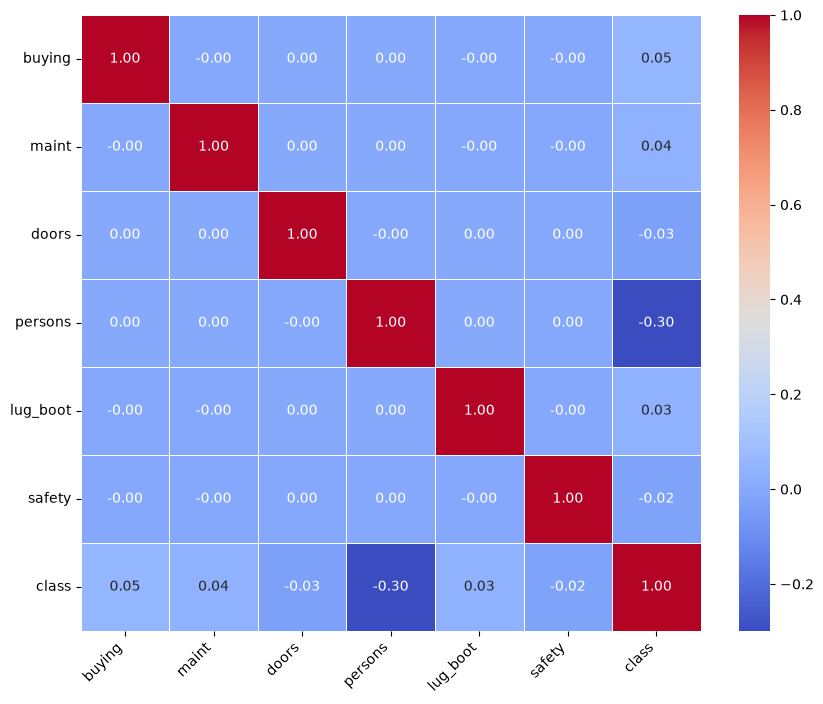

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))  # کمی ارتفاع رو بیشتر کردیم

sns.heatmap(
    data.corr(),
    annot=True,
    fmt=".2f",  # نمایش با دو رقم اعشار برای جلوگیری از شلوغی
    cmap="coolwarm",  # پالت رنگی جذاب‌تر و خواناتر
    linewidths=0.5,  # فاصله بین خانه‌ها
    annot_kws={"size": 10},  # تنظیم سایز فونت اعداد داخل جدول
)

plt.xticks(rotation=45, ha="right")  # چرخش نام ستون‌ها برای خوانایی بهتر
plt.yticks(rotation=0)
plt.show()


In [15]:
x = data.drop("class" , axis=1)
y= data["class"]

x_train , x_test ,y_train ,  y_test = train_test_split(x , y , random_state=42 , test_size=0.2
)



In [16]:
model_tree = tree.DecisionTreeClassifier()
model_tree.fit(x_train,y_train)
y_pred_tree = model_tree.predict(x_test)

accuracy = metrics.accuracy_score(y_test, y_pred_tree) * 100
print(f"Accuracy: {accuracy:.2f}%")



Accuracy: 97.11%


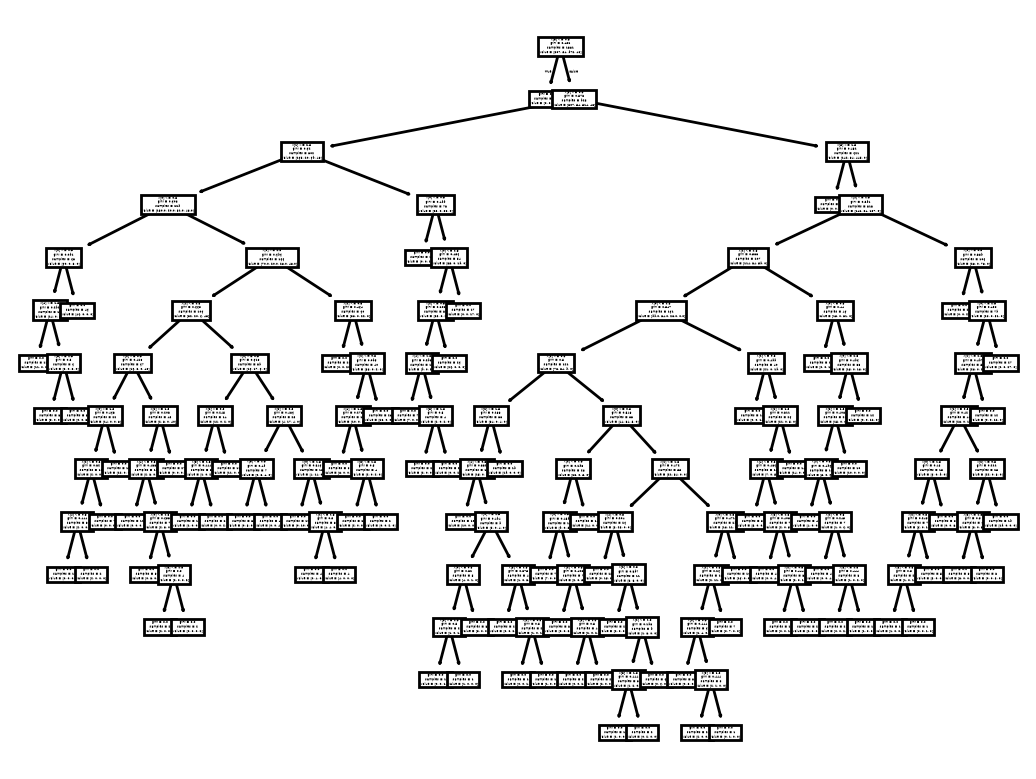

In [17]:
%config InlineBackend.figure_format = 'retina'

tree.plot_tree(model_tree)
plt.show()